In [1]:
%% Homework 3
% Ely Dawson
% Due: 22 Oct 2026

Executing ...

In [27]:
%% 1: Plot the time series of wind speed, wave height, water temperature, 
% and air temperature from 46047. Since the data are text files with a
% header, in Matlab you can read with: importdata
% Read the help page. You’ll want to specify a blank space delimiter between files
% and 2 header lines.

%% How are missing data identified in the records?
% The missing data is filled by using either 99 or 999 entry values. 
% They are using numbers so unbelievably large that there is no mistake on if it is real entry. 
% Wave height definitely has the most missing data points of the three variables. 
% The graphs are a little silly to look at. 

In [62]:
file15 = '46047h2015.txt';
file16 = '46047h2016.txt';
dlim = ' ';
header = 2;

T15 = importdata(file15, dlim, header);
T16 = importdata(file16, dlim, header);

% continuous record
T = [T15.data; T16.data];
data = T;
T = struct();
T.data = data;
T.date = datetime(T.data(:,1), T.data(:,2), T.data(:,3), T.data(:,4), T.data(:,5), 0, 'TimeZone', 'UTC');
T.posix = posixtime(T.date);
T.wspd = T.data(:,7);
T.wvht = T.data(:,9);
T.wtmp = T.data(:,15);
T.atmp = T.data(:,14);

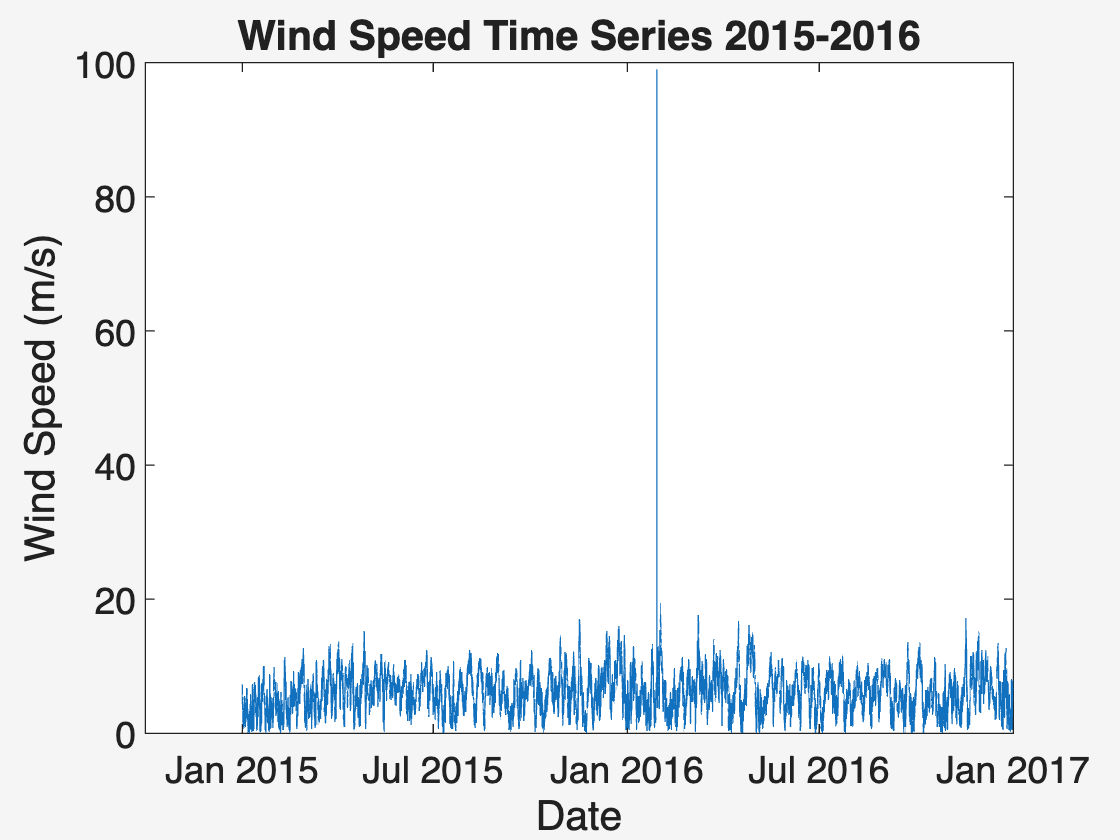

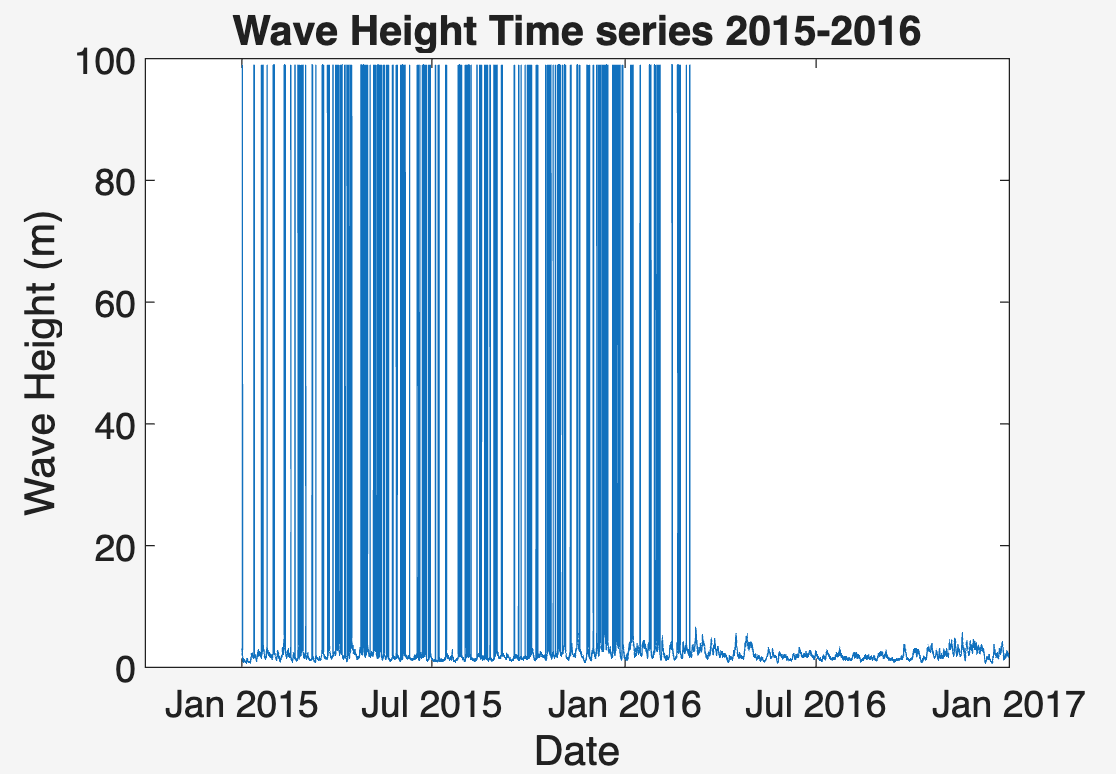

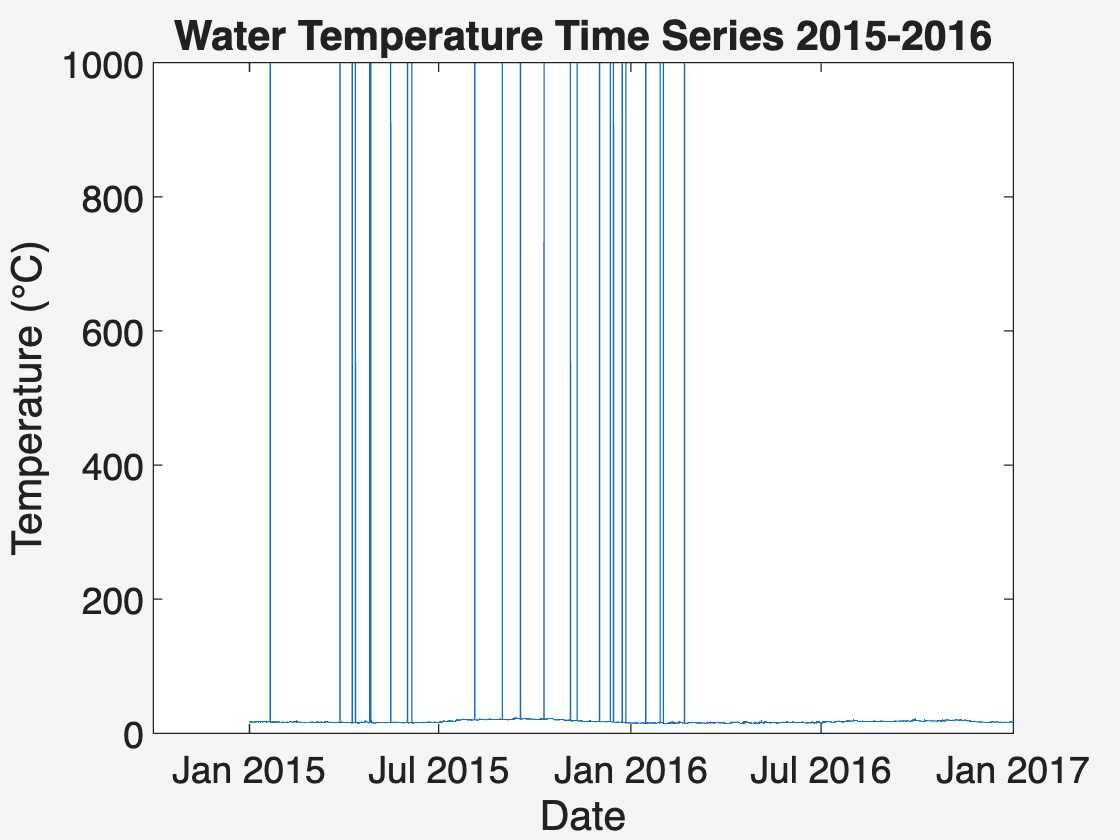

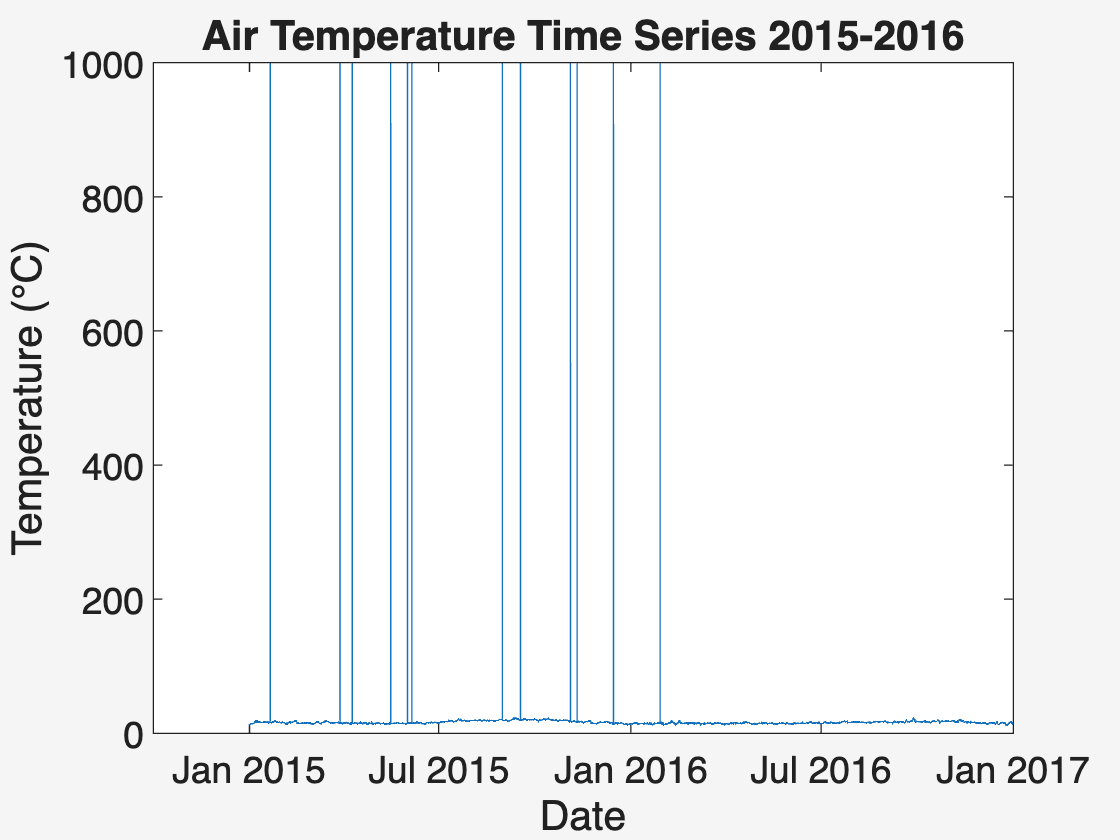

In [65]:
% Plot the time series for wind speed, wave height, water temp
figure (1); clf;
plot(T.date, T.wspd);
title('Wind Speed Time Series 2015-2016');
ylabel('Wind Speed (m/s)')
xlabel('Date')

figure (2); clf;
plot(T.date, T.wvht);
title('Wave Height Time series 2015-2016');
ylabel('Wave Height (m)')
xlabel('Date')

figure(3); clf;
plot(T.date, T.wtmp);
title('Water Temperature Time Series 2015-2016');
ylabel('Temperature (°C)')
xlabel('Date')

figure(4); clf;
plot(T.date, T.atmp);
title('Air Temperature Time Series 2015-2016');
ylabel('Temperature (°C)')
xlabel('Date')

In [30]:
%% 2: Monthly means. 
% Since there’s quite a bit of variability, average the data to
% produce monthly means for 2015 and 2016. Plot the means for each month and
% standard error of the mean. Data are provided at varying frequencies, but consecutive 
% data are not independent. For the purposes of this problem set, let’s assume
% that the data provide one independent sample every 7 days. Hint: In Matlab, use: errorbar
% to plot the data with uncertainty ranges.

In [66]:
T.wspd(T.wspd == 99) = nan;
T.wvht(T.wvht == 99) = nan;
T.wtmp(T.wtmp == 999) = nan;
T.atmp(T.atmp == 999) = nan;

years = [2015, 2016];
m_mean_wspd = nan(12,2);
m_mean_wvht = nan(12,2);
m_mean_wtmp = nan(12,2);
m_mean_atmp = nan(12,2);
m_sem_wspd = nan(12,2);
m_sem_wvht = nan(12,2);
m_sem_wtmp = nan(12,2);
m_sem_atmp = nan(12,2);

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wspd(idx);
        values = values(isfinite(values));
        m_mean_wspd(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wspd(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wvht(idx);
        values = values(isfinite(values));
        m_mean_wvht(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wvht(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.wtmp(idx);
        values = values(isfinite(values));
        m_mean_wtmp(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_wtmp(m,k) = std(values) / sqrt(nind);
    end
end

for k = 1:numel(years)
    for m = 1:12
        idx = year(T.date) == years(k) & month(T.date) == m;
        values = T.atmp(idx);
        values = values(isfinite(values));
        m_mean_atmp(m,k) = mean(values);
        n = numel(values);
        dm = day(datetime(years(k),m+1,1) - caldays(1));
        nind = min(n, dm / 7);
        m_sem_atmp(m,k) = std(values) / sqrt(nind);
    end
end

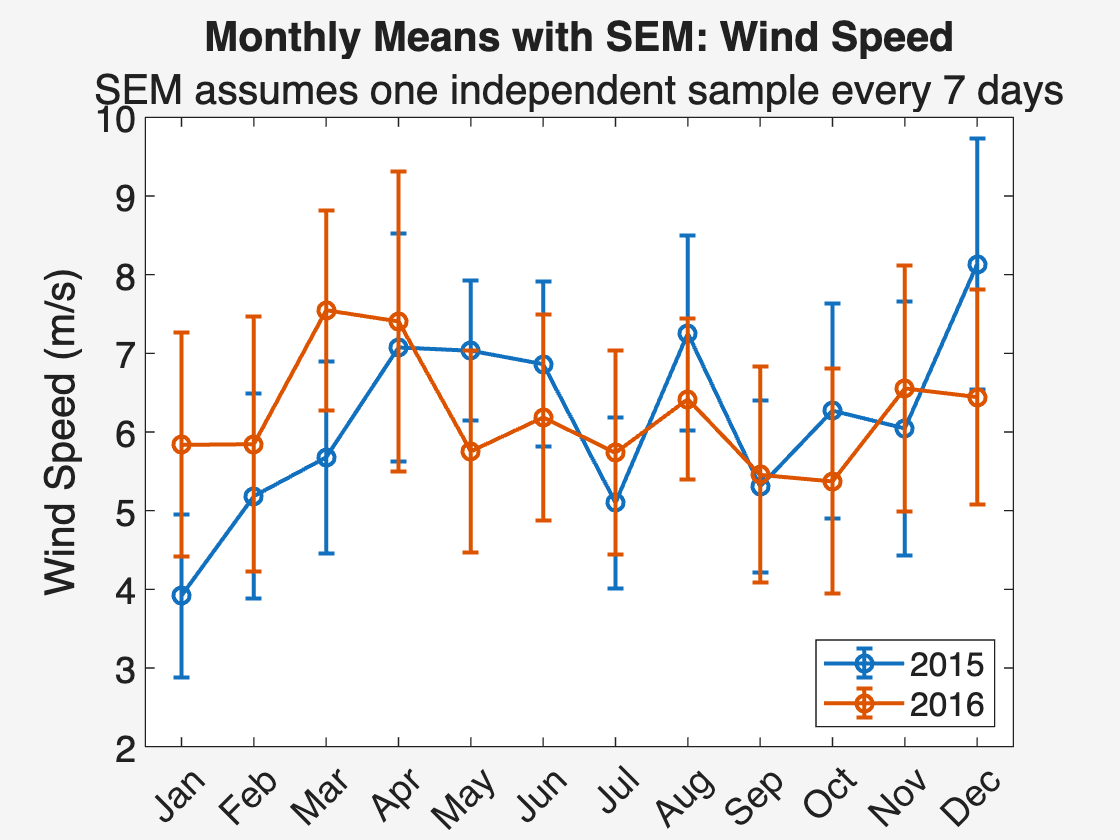

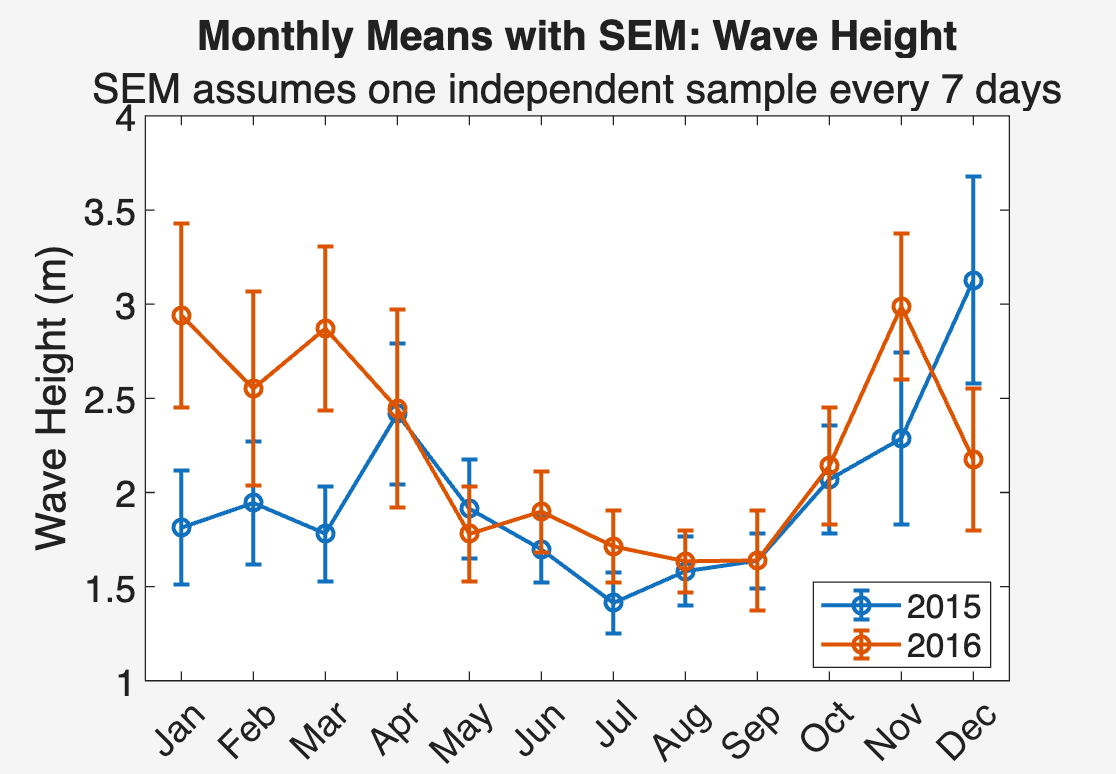

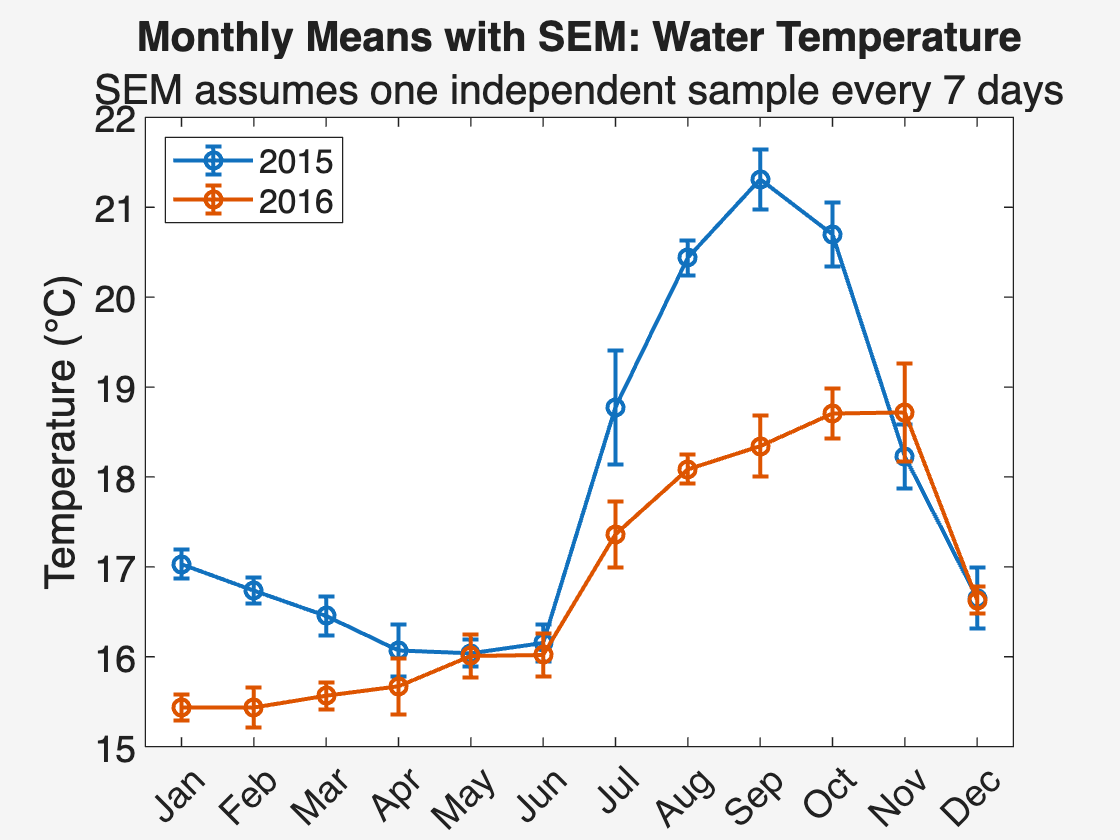

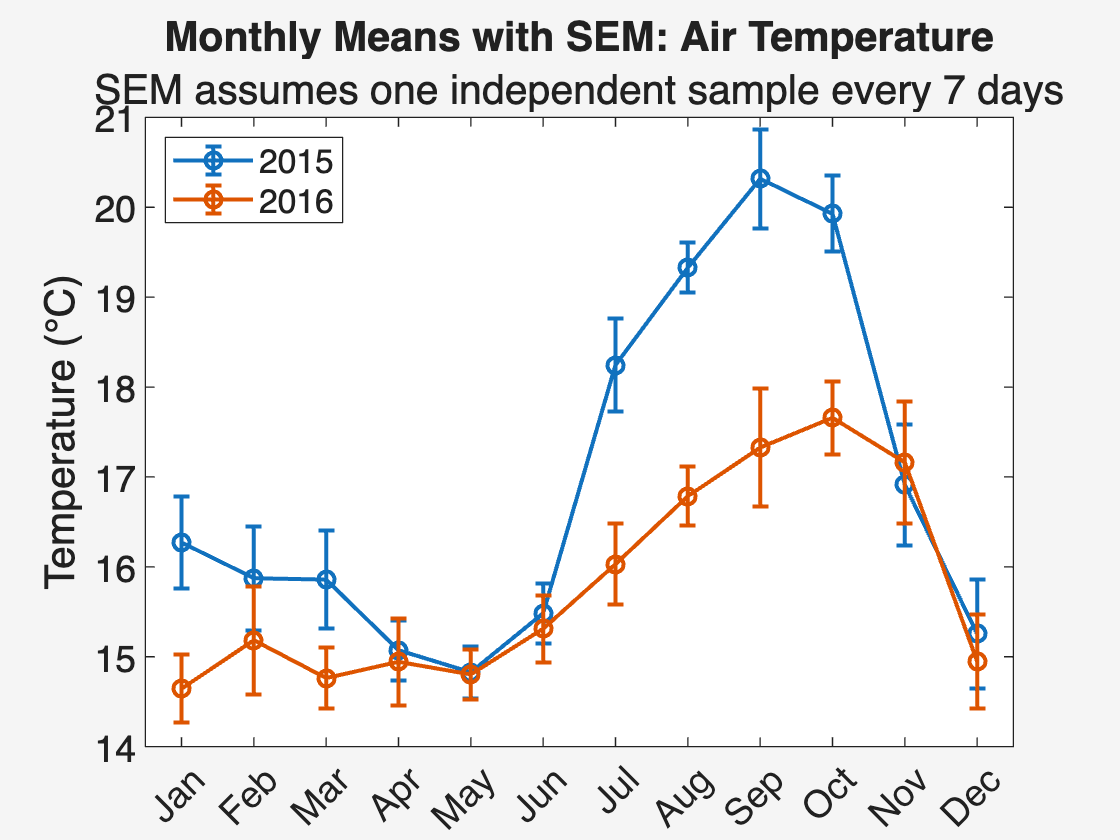

In [68]:
% Plotting time
figure(1); clf;
errorbar(1:12, m_mean_wspd(:,1), m_sem_wspd(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wspd(:,2), m_sem_wspd(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Wind Speed (m/s)')
title('Monthly Means with SEM: Wind Speed')
subtitle('SEM assumes one independent sample every 7 days') 
hold off;

figure(2); clf;
errorbar(1:12, m_mean_wvht(:,1), m_sem_wvht(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wvht(:,2), m_sem_wvht(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Wave Height (m)')
title('Monthly Means with SEM: Wave Height')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

figure(3); clf;
errorbar(1:12, m_mean_wtmp(:,1), m_sem_wtmp(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_wtmp(:,2), m_sem_wtmp(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Temperature (°C)')
title('Monthly Means with SEM: Water Temperature')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

figure(4); clf;
errorbar(1:12, m_mean_atmp(:,1), m_sem_atmp(:,1),'-o', 'LineWidth', 1.5, 'DisplayName', '2015');
hold on
errorbar(1:12, m_mean_atmp(:,2), m_sem_atmp(:,2),'-o', 'LineWidth', 1.5, 'DisplayName', '2016');
legend('Location','best')
xticks(1:1:12)
xlim([0.5 12.5])
xticklabels({'Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'});
ylabel('Temperature (°C)')
title('Monthly Means with SEM: Air Temperature')
subtitle('SEM assumes one independent sample every 7 days') 
hold off

In [78]:
%% 3: Least-squares fit. 
% Treating the two years separately, least-squares fit a mean
% and an annual cycle to the four data records. 

%% What is the mean, and what is the amplitude of the annual cycle? 
% (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.) 
% The means and amplitudes are as follows for each variable:
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water temperature','Air temperature'};
units = {'m/s','m','°C','°C'};

for k = 1:numel(years)
    yrField = sprintf('yr_%d', years(k));
    fprintf('\n--- %d ---\n', years(k));

    for v = 1:numel(vars)
        result = fitResults.(vars{v}).(yrField);

        fprintf('%s: Mean = %.3f %s, Annual amplitude = %.3f %s\n', ...
            names{v}, result.mean, units{v}, ...
            result.amplitude, units{v});
    end
end
 

%% Are the fitted coefficients similar for the two years?



--- 2015 ---
Wind speed: Mean = 6.161 m/s, Annual amplitude = 0.372 m/s
Wave height: Mean = 1.968 m, Annual amplitude = 0.369 m
Water temperature: Mean = 17.892 °C, Annual amplitude = 2.415 °C
Air temperature: Mean = 16.957 °C, Annual amplitude = 2.333 °C

--- 2016 ---
Wind speed: Mean = 6.213 m/s, Annual amplitude = 0.435 m/s
Wave height: Mean = 2.229 m, Annual amplitude = 0.570 m
Water temperature: Mean = 16.835 °C, Annual amplitude = 1.690 °C
Air temperature: Mean = 15.795 °C, Annual amplitude = 1.395 °C


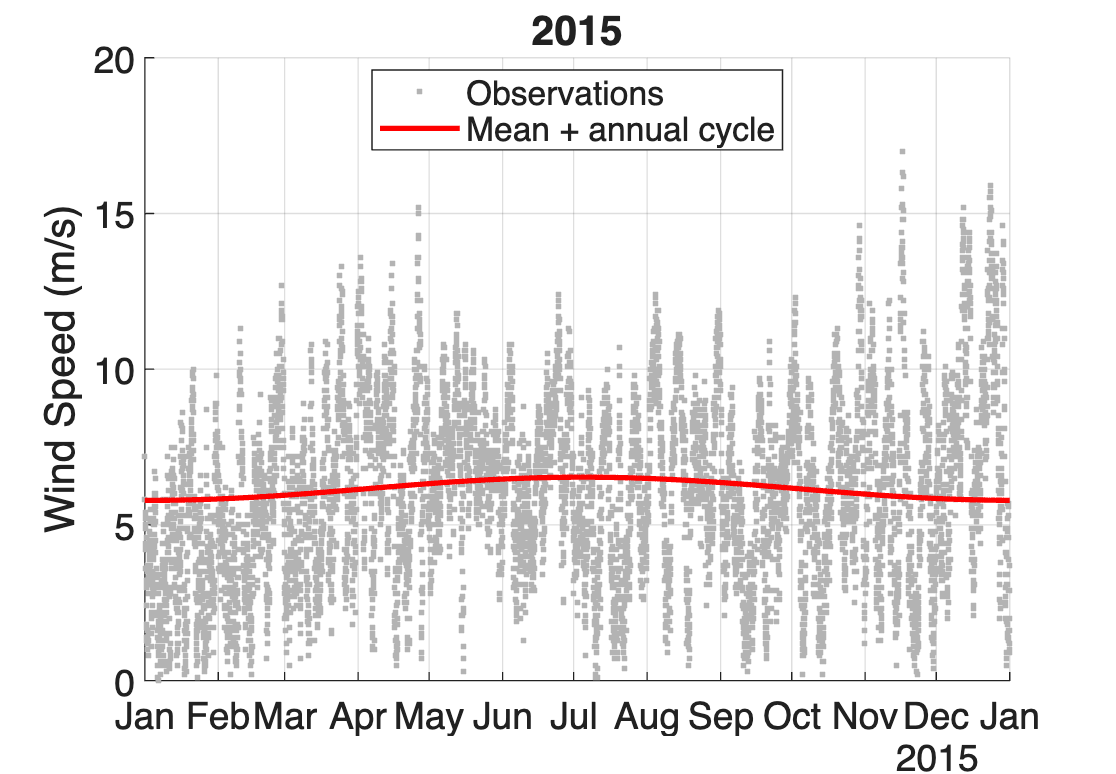

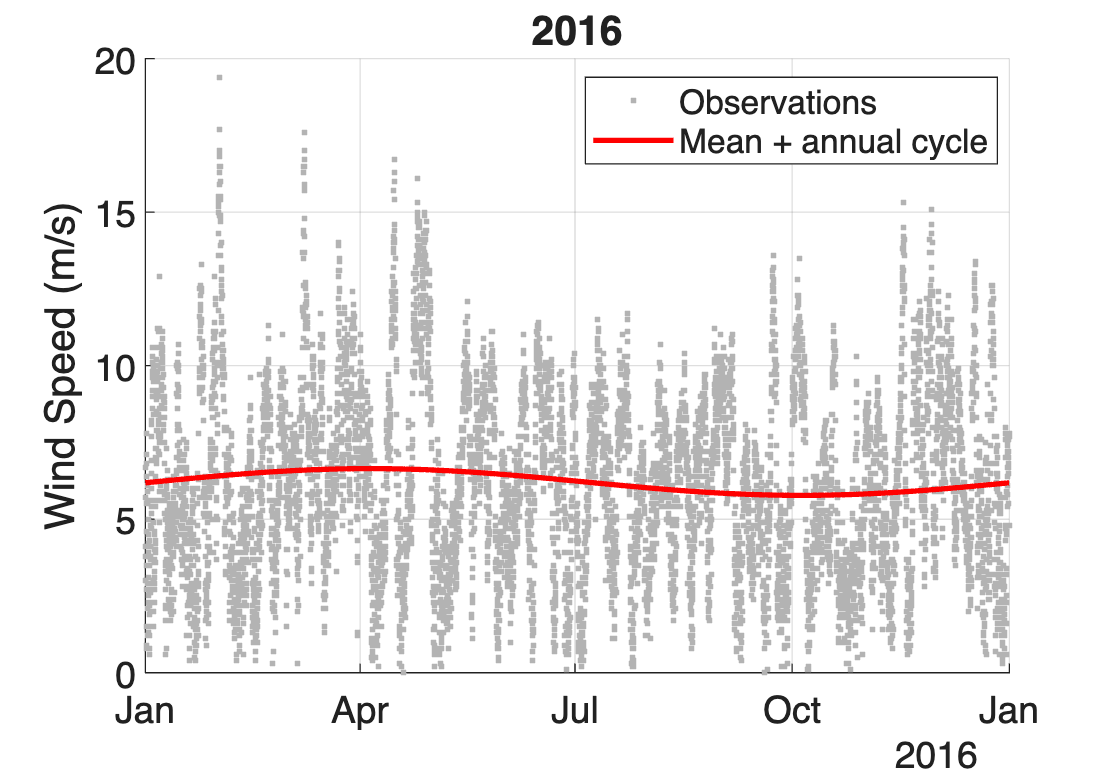

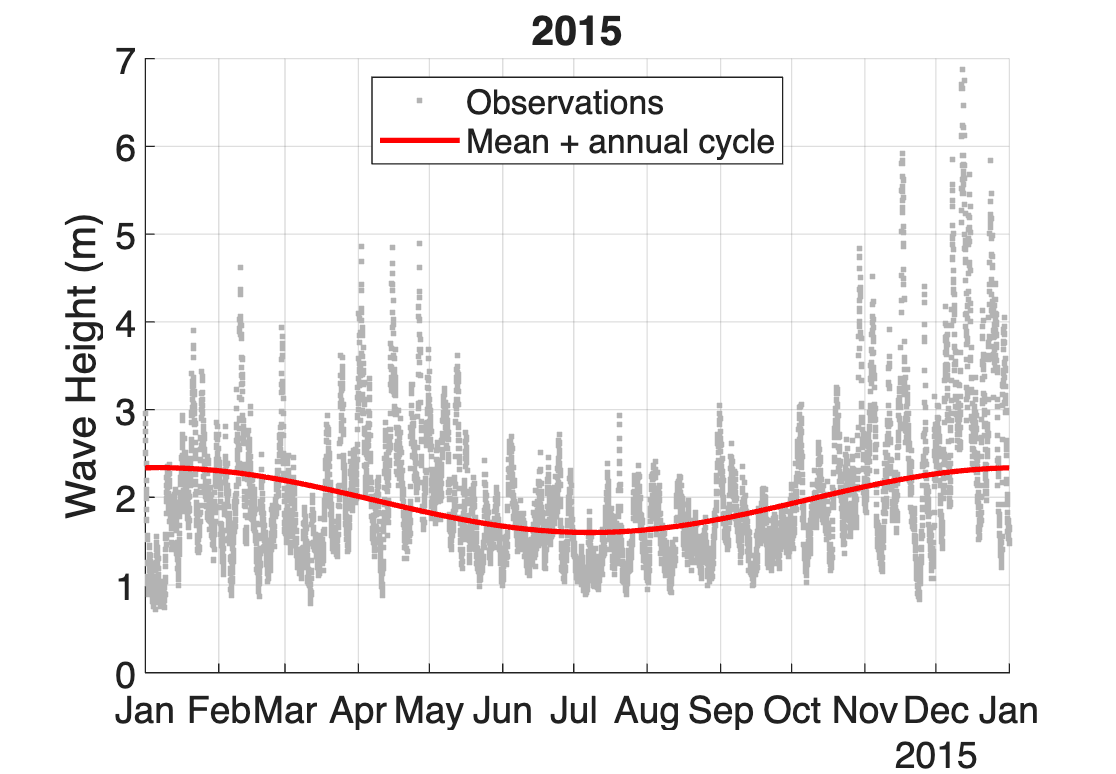

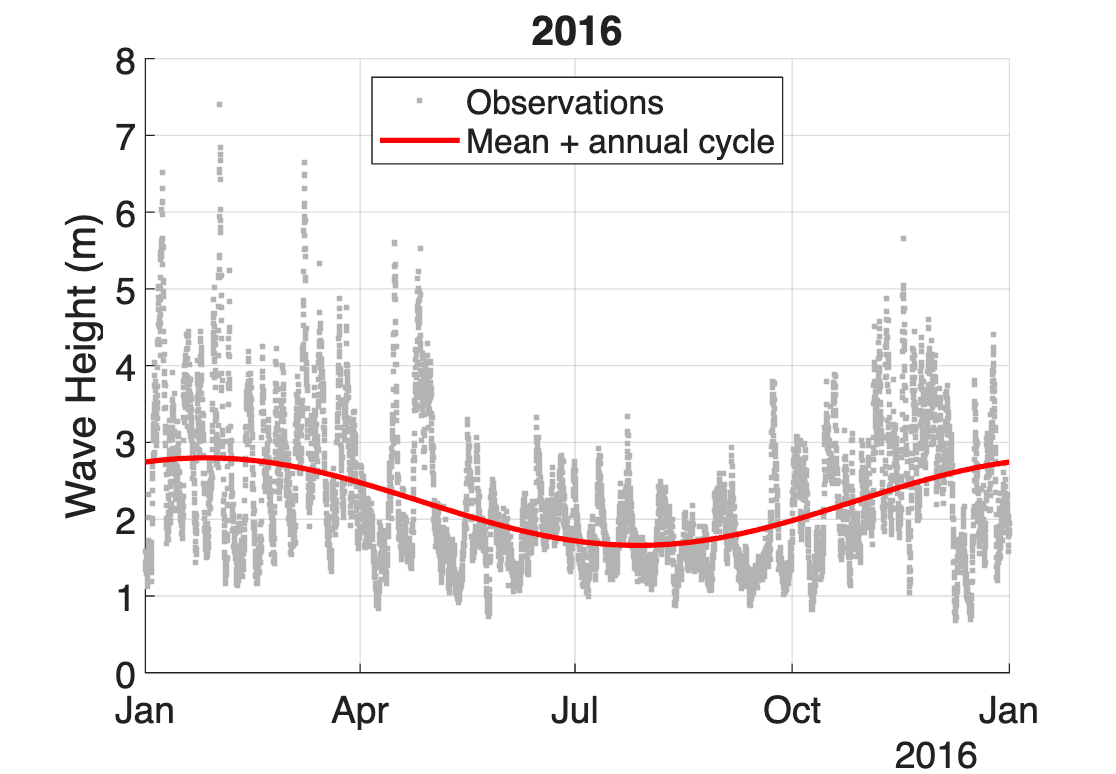

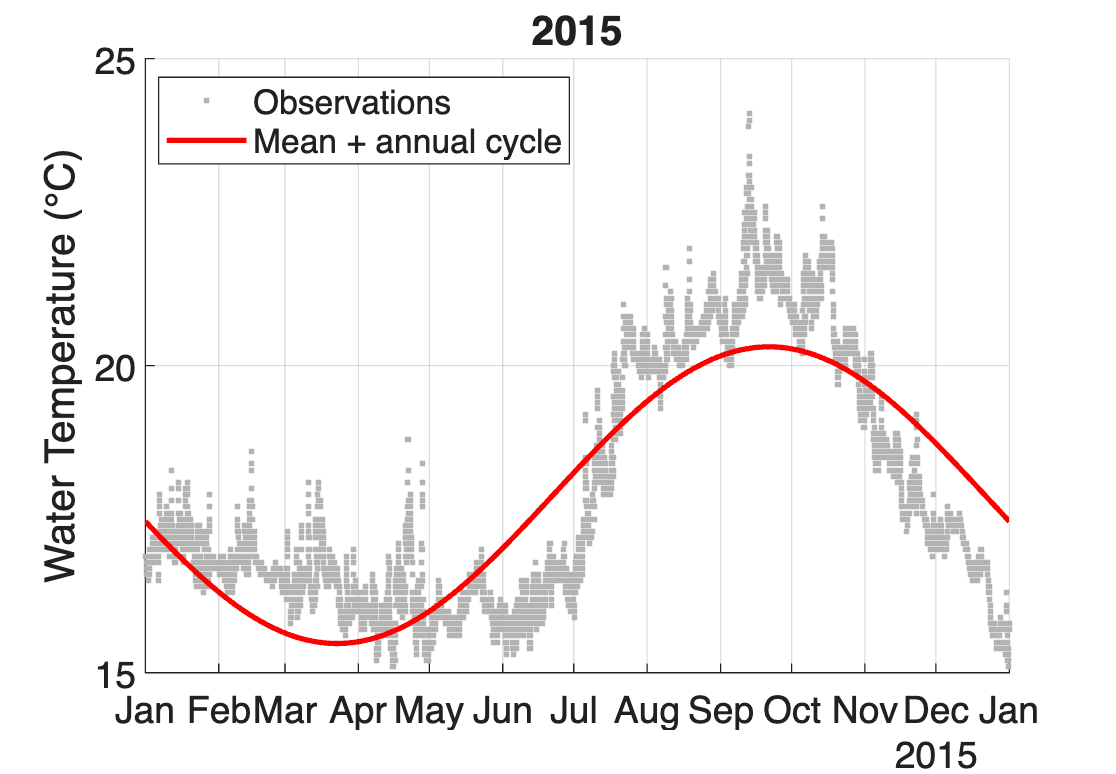

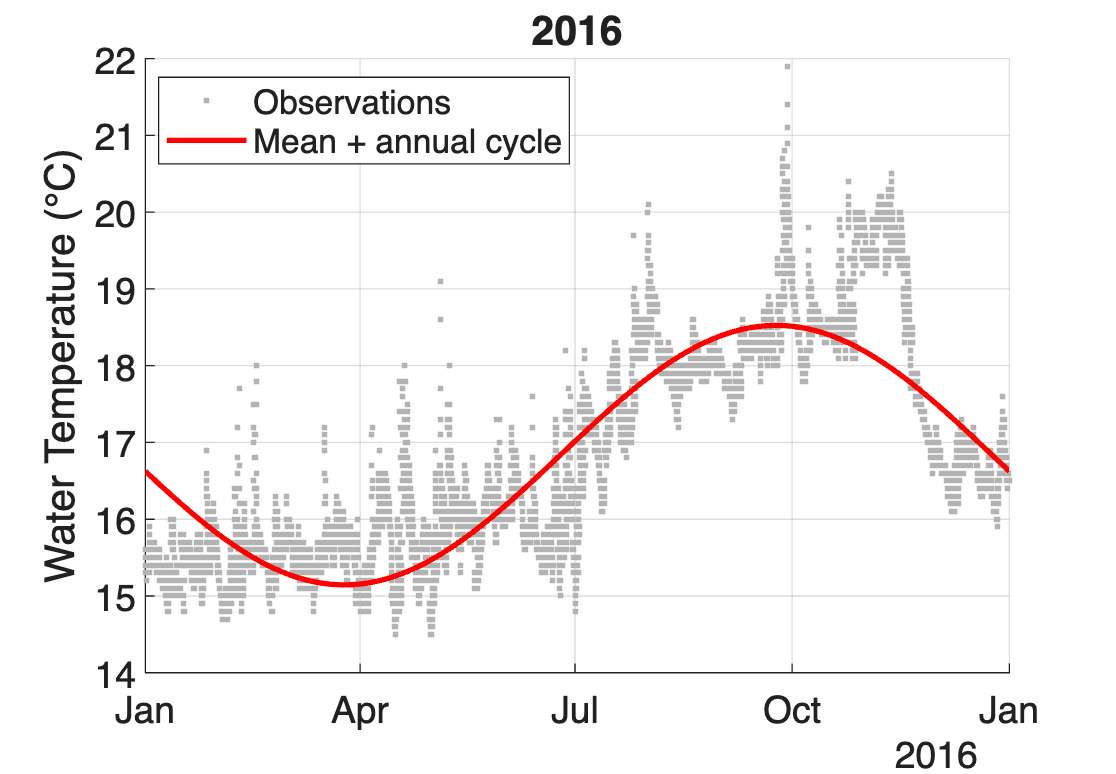

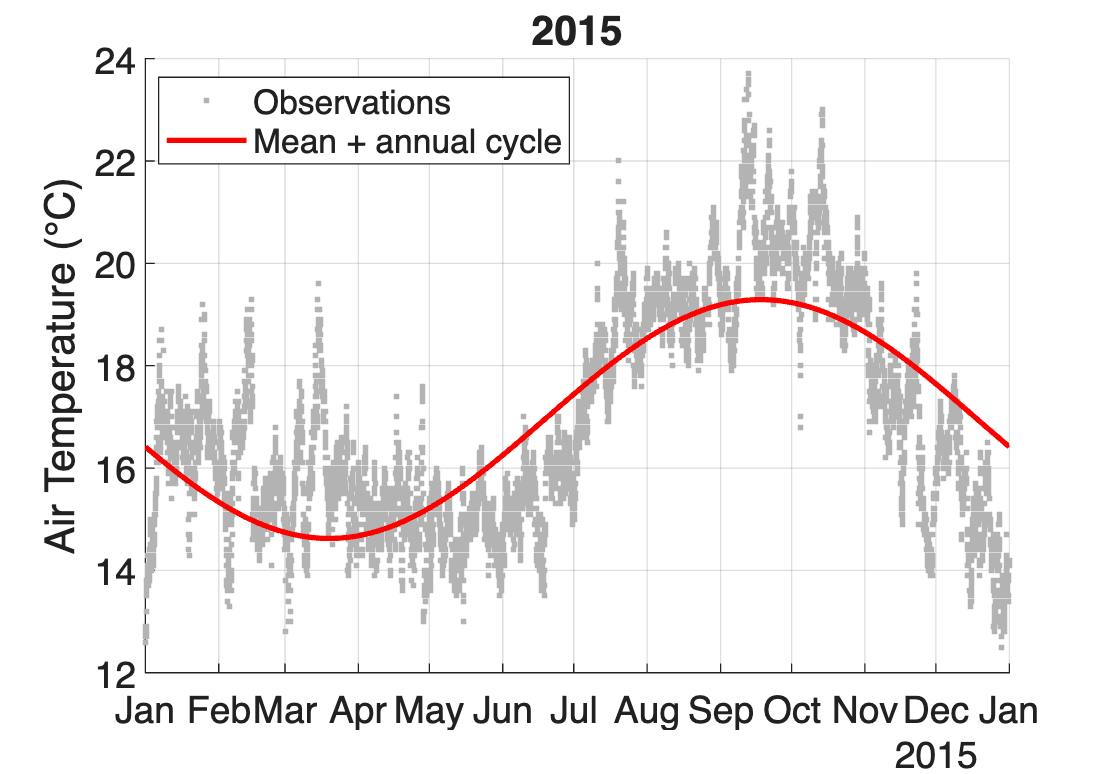

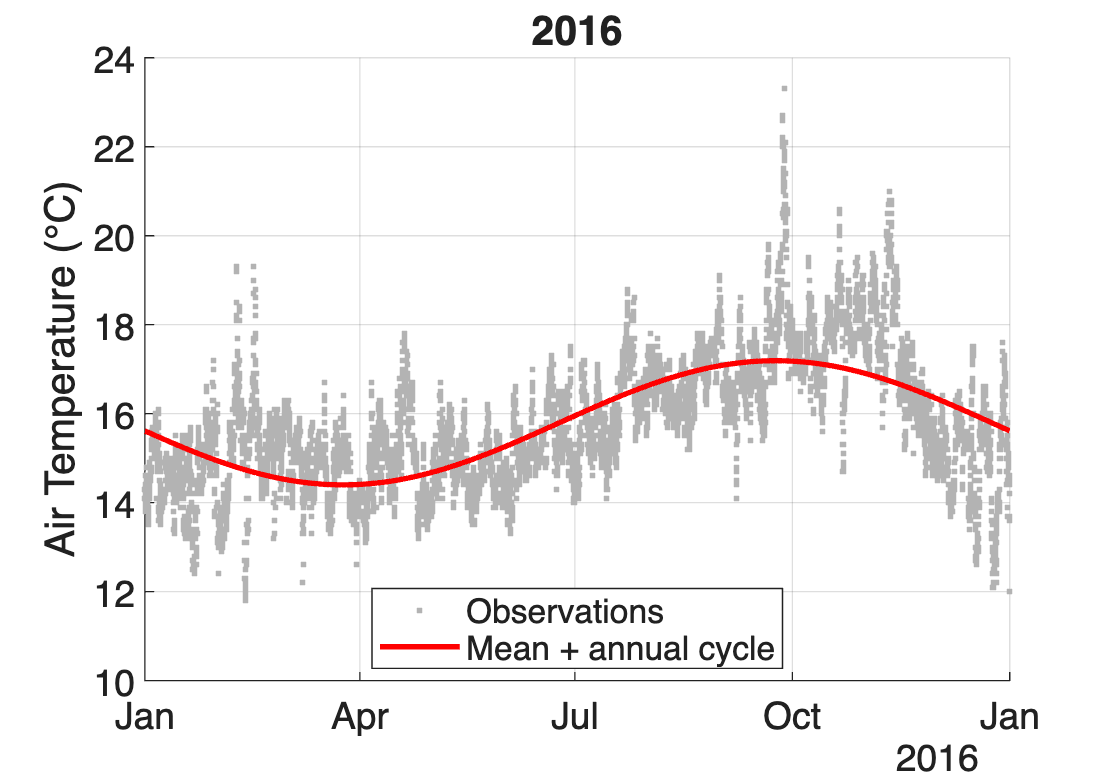

In [76]:
years = [2015, 2016];
vars  = {'wspd','wvht','wtmp','atmp'};
names = {'Wind Speed','Wave Height','Water Temperature','Air Temperature'};
units = {'m/s','m','°C','°C'};
fitResults = struct();
figure; clf;

for v = 1:numel(vars)
    for k = 1:numel(years)
        figure;
        hold on;

        x = T.(vars{v});
        idx = year(T.date) == years(k) & isfinite(x);

        dates = T.date(idx);
        values = x(idx);
        dates = dates(:);
        values = values(:);

        t0 = datetime(years(k),1,1, 'TimeZone',T.date.TimeZone);
        t1 = datetime(years(k)+1,1,1, 'TimeZone',T.date.TimeZone);

        t = seconds(dates - t0) / seconds(t1 - t0);

        G = [ones(size(t)), cos(2*pi*t), sin(2*pi*t)];

        coef = G \ values;

        yrField = sprintf('yr_%d', years(k));
        fitResults.(vars{v}).(yrField).mean = coef(1);
        fitResults.(vars{v}).(yrField).cosCoef = coef(2);
        fitResults.(vars{v}).(yrField).sinCoef = coef(3);
        fitResults.(vars{v}).(yrField).amplitude = hypot(coef(2),coef(3));

        tFit = linspace(0,1,366)';
        datesFit = t0 + seconds(tFit * seconds(t1 - t0));
        yFit = coef(1) + coef(2)*cos(2*pi*tFit) + coef(3)*sin(2*pi*tFit);

        plot(dates, values, '.', 'Color',[0.7 0.7 0.7],'DisplayName','Observations');
        plot(datesFit, yFit, 'r-', 'LineWidth',2,'DisplayName','Mean + annual cycle');

        xlim([t0 t1]);
        xtickformat('MMM');
        ylabel(sprintf('%s (%s)', names{v}, units{v}));
        title(sprintf('%d', years(k)));
        grid on;
        
        legend('Location','best');
    end
end